#### Classification

In [26]:
import pandas as pd 
import numpy as np 

In [5]:
# data set of loan 
data = pd.read_csv("D:/CODING/ML using Python/CompleteMachineLearningwithPython/Complete Machine Learning with Python/Practise set data file/Loan.xlsx - loan_data.csv",header=0)
data_backup = data.copy()

In [6]:
data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,Yes,1,Graduate,No,4583,1508.0,128,360.0,1.0,Rural,N
1,Male,Yes,0,Graduate,Yes,3000,0.0,66,360.0,1.0,Urban,Y
2,Male,Yes,0,Not Graduate,No,2583,2358.0,120,360.0,1.0,Urban,Y
3,Male,No,0,Graduate,No,6000,0.0,141,360.0,1.0,Urban,Y
4,Male,Yes,0,Not Graduate,No,2333,1516.0,95,360.0,1.0,Urban,Y


In [7]:
# findng the missing values 
data.isnull().sum()

Gender                5
Married               0
Dependents            8
Education             0
Self_Employed        21
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     11
Credit_History       30
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             376 non-null    object 
 1   Married            381 non-null    object 
 2   Dependents         373 non-null    object 
 3   Education          381 non-null    object 
 4   Self_Employed      360 non-null    object 
 5   ApplicantIncome    381 non-null    int64  
 6   CoapplicantIncome  381 non-null    float64
 7   LoanAmount         381 non-null    int64  
 8   Loan_Amount_Term   370 non-null    float64
 9   Credit_History     351 non-null    float64
 10  Property_Area      381 non-null    object 
 11  Loan_Status        381 non-null    object 
dtypes: float64(3), int64(2), object(7)
memory usage: 35.8+ KB


In [9]:
# filling the numerical data values 
for col in ['Credit_History', 'Loan_Amount_Term']:
    data[col] = data[col].fillna(data[col].mean())

for col in ['Gender', 'Dependents', 'Self_Employed']:
    data[col] = data[col].fillna(data[col].mode()[0])

In [10]:
data.isnull().sum() # value imputed 

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

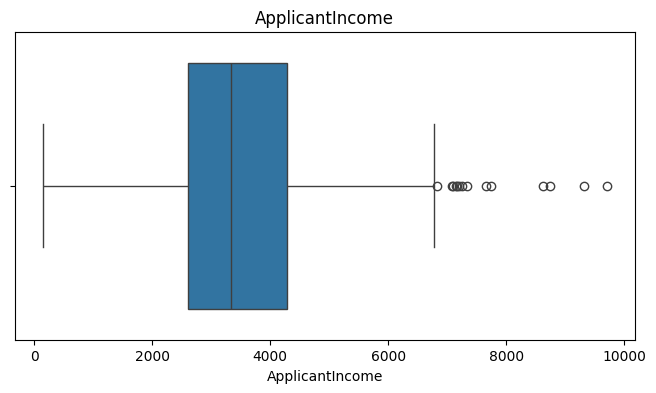

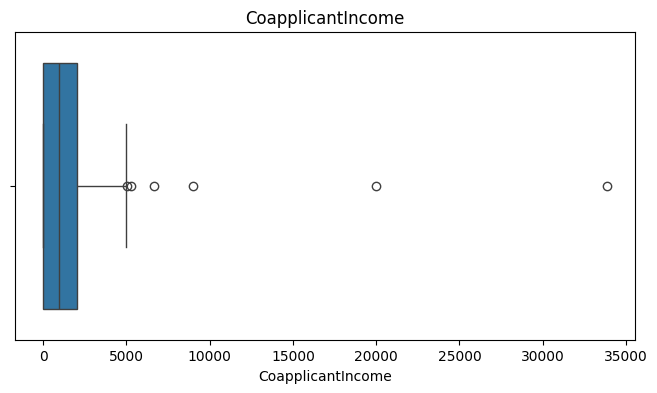

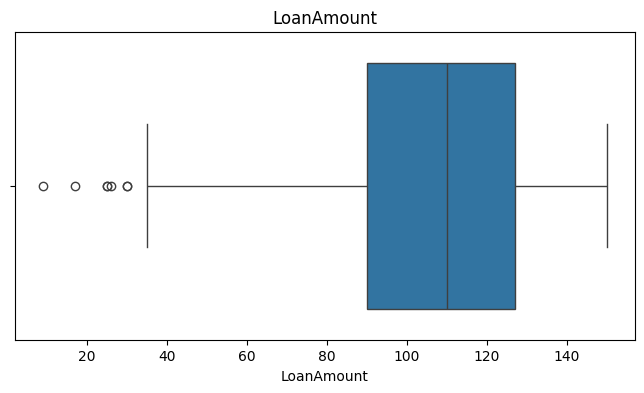

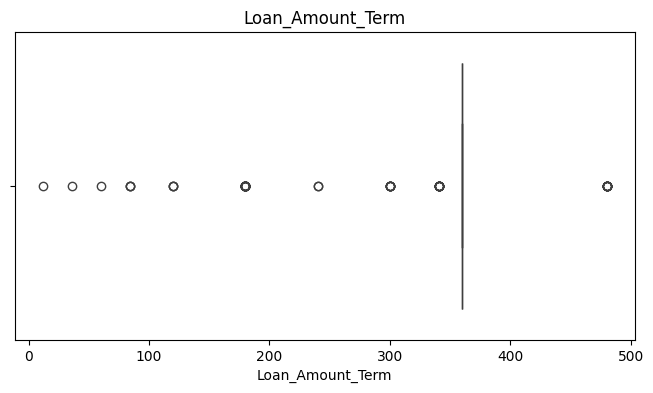

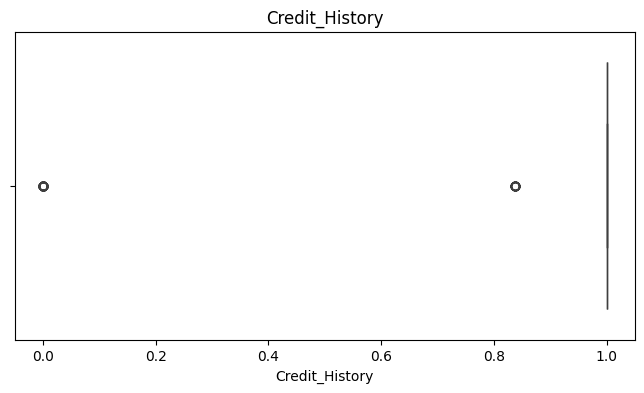

In [11]:
import matplotlib.pyplot as plt # this shows the outliers in the data set 
import seaborn as sns

for col in data.select_dtypes(include=['int64', 'float64']).columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=data[col])
    plt.title(data[col].name)
    plt.show()

In [12]:
df = pd.get_dummies(data, columns=data.select_dtypes(include=['object']).columns, drop_first=True).astype(int)

In [13]:
df.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Loan_Status_Y
0,4583,1508,128,360,1,1,1,1,0,0,0,0,0,0,0
1,3000,0,66,360,1,1,1,0,0,0,0,1,0,1,1
2,2583,2358,120,360,1,1,1,0,0,0,1,0,0,1,1
3,6000,0,141,360,1,1,0,0,0,0,0,0,0,1,1
4,2333,1516,95,360,1,1,1,0,0,0,1,0,0,1,1


<Axes: xlabel='ApplicantIncome', ylabel='CoapplicantIncome'>

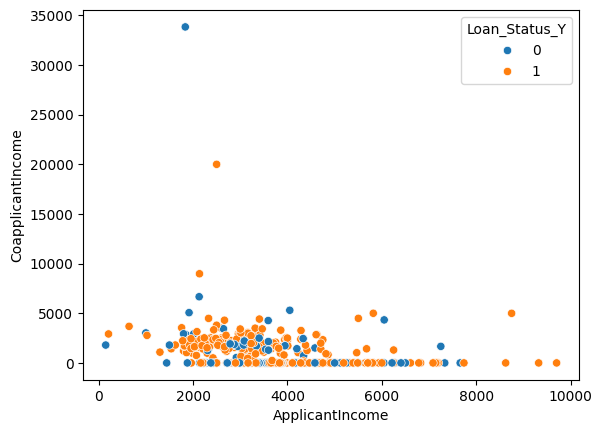

In [14]:
sns.scatterplot(x='ApplicantIncome', y='CoapplicantIncome',hue= 'Loan_Status_Y', data=df)

<Axes: xlabel='ApplicantIncome', ylabel='Loan_Status_Y'>

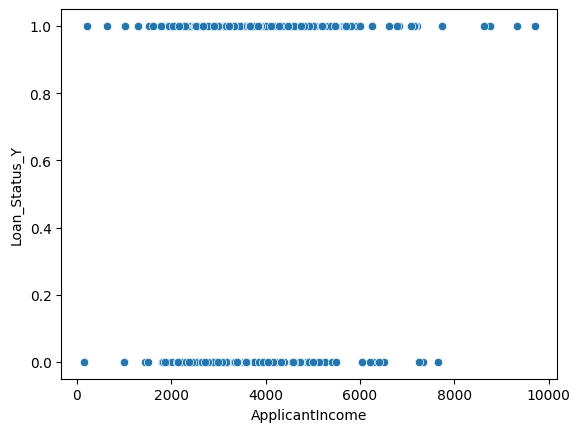

In [15]:
sns.scatterplot(x='ApplicantIncome', y='Loan_Status_Y', data=df) # there is no oulier in the data set 

In [16]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Loan_Status_Y
count,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000
mean,3579.845144,1277.272966,104.986877,340.839895,0.771654,0.776903,0.598425,0.136483,0.154856,0.073491,0.270341,0.091864,0.391076,0.330709,0.711286
std,1419.813818,2340.818546,28.358464,67.549967,0.420319,0.416870,0.490861,0.343752,0.362243,0.261284,0.444720,0.289213,0.488633,0.471087,0.453761
min,150.000000,0.000000,9.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2600.000000,0.000000,90.000000,360.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3333.000000,983.000000,110.000000,360.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,4288.000000,2016.000000,127.000000,360.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,9703.000000,33837.000000,150.000000,480.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


*Logistic Regression*

In [17]:
# now its time for the model 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

In [18]:
x = df.drop('Loan_Status_Y', axis=1) 
y = df['Loan_Status_Y']

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y, shuffle=True)

In [59]:
# scaling the data 
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()
x_train_scal = scaler.fit_transform(x_train)
x_test_scal = scaler.transform(x_test)

In [60]:
lr = LogisticRegression()
#lr.fit(x_train, y_train)
lr.fit(x_train_scal, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [61]:
y_train_pred =lr.predict(x_train_scal)
y_test_pred = lr.predict(x_test_scal)

In [62]:
# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

Train Accuracy:-  0.7763157894736842
f1_score:-  0.8502202643171806
precision_score:-  0.8109243697478992
recall_score:-  0.8935185185185185
confusion matrix:-  [[ 43  45]
 [ 23 193]]


In [64]:
# testing evaluation
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Test Accuracy:-  0.8441558441558441
f1_score:-  0.9
precision_score:-  0.8307692307692308
recall_score:-  0.9818181818181818
confusion matrix:-  [[11 11]
 [ 1 54]]


*LDA*

In [49]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [50]:
lda = LinearDiscriminantAnalysis()

In [51]:
lda.fit(x_train, y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [58]:
y_train_pred =lda.predict(x_train)
y_test_pred = lda.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.7730263157894737
f1_score:-  0.8463251670378619
precision_score:-  0.8154506437768241
recall_score:-  0.8796296296296297
confusion matrix:-  [[ 45  43]
 [ 26 190]]
Test Accuracy:-  0.8441558441558441
f1_score:-  0.8983050847457628
precision_score:-  0.8412698412698413
recall_score:-  0.9636363636363636
confusion matrix:-  [[12 10]
 [ 2 53]]


*KNN*

In [93]:
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.preprocessing import StandardScaler

scaler= StandardScaler() # standardize data
scaler.fit(x_train)
scaler.fit(x_test)

x_train_scale = scaler.transform(x_train)
x_test_scale = scaler.transform(x_test)

knn = KNeighborsClassifier()
knn.fit(x_train_scale, y_train)

y_train_pred =knn.predict(x_train_scale)
y_test_pred = knn.predict(x_test_scale)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.7894736842105263
f1_score:-  0.8620689655172413
precision_score:-  0.8064516129032258
recall_score:-  0.9259259259259259
confusion matrix:-  [[ 40  48]
 [ 16 200]]
Test Accuracy:-  0.8181818181818182
f1_score:-  0.8833333333333333
precision_score:-  0.8153846153846154
recall_score:-  0.9636363636363636
confusion matrix:-  [[10 12]
 [ 2 53]]


*Decision Tree* 

In [28]:
from sklearn.tree import DecisionTreeClassifier 

dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)

y_train_pred =dt.predict(x_train)
y_test_pred = dt.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  1.0
f1_score:-  1.0
precision_score:-  1.0
recall_score:-  1.0
confusion matrix:-  [[ 89   0]
 [  0 215]]
Test Accuracy:-  0.6233766233766234
f1_score:-  0.7387387387387387
precision_score:-  0.7454545454545455
recall_score:-  0.7321428571428571
confusion matrix:-  [[ 7 14]
 [15 41]]


In [ ]:
# the training evaluation is good but the testing evaluation is not good. its overfitting 

dt2 = DecisionTreeClassifier(max_depth=2) # apply tree pruining 
dt2.fit(x_train, y_train)

y_train_pred =dt2.predict(x_train)
y_test_pred = dt2.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.8092105263157895
f1_score:-  0.8733624454148472
precision_score:-  0.823045267489712
recall_score:-  0.9302325581395349
confusion matrix:-  [[ 46  43]
 [ 15 200]]
Test Accuracy:-  0.7272727272727273
f1_score:-  0.8264462809917356
precision_score:-  0.7692307692307693
recall_score:-  0.8928571428571429
confusion matrix:-  [[ 6 15]
 [ 6 50]]


*Random Forest*

In [91]:
from sklearn.ensemble import RandomForestClassifier 

rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)

y_train_pred =rf.predict(x_train)
y_test_pred = rf.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  1.0
f1_score:-  1.0
precision_score:-  1.0
recall_score:-  1.0
confusion matrix:-  [[ 88   0]
 [  0 216]]
Test Accuracy:-  0.8311688311688312
f1_score:-  0.8888888888888888
precision_score:-  0.8387096774193549
recall_score:-  0.9454545454545454
confusion matrix:-  [[12 10]
 [ 3 52]]


In [92]:
# this is also overfit the data 
rf2 = RandomForestClassifier(max_depth=5, min_samples_split=2, min_samples_leaf=4, n_estimators=200, n_jobs=-1, random_state=42)
rf2.fit(x_train, y_train)

y_train_pred =rf2.predict(x_train)
y_test_pred = rf2.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.8256578947368421
f1_score:-  0.8888888888888888
precision_score:-  0.8122605363984674
recall_score:-  0.9814814814814815
confusion matrix:-  [[ 39  49]
 [  4 212]]
Test Accuracy:-  0.7792207792207793
f1_score:-  0.8661417322834646
precision_score:-  0.7638888888888888
recall_score:-  1.0
confusion matrix:-  [[ 5 17]
 [ 0 55]]


*Grid Search CV for Hyperparameter tuning*

In [29]:
from sklearn.model_selection import GridSearchCV

param = {
          'max_depth':[2,5],
          'min_samples_split':[2,3,4,5],
          'min_samples_leaf':[1,2,3,4]
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param, cv=3, n_jobs=-1, verbose=2)
grid.fit(x_train, y_train)

# best pramater and score 
best_param = grid.best_params_
score = grid.best_score_
print('Best score', score)
print("Best parameter:- ", best_param)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best score 0.7763541059988351
Best parameter:-  {'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [ ]:
#model = grid.best_estimator_
model = DecisionTreeClassifier(**best_param)
model.fit(x_train, y_train)

y_train_pred =model.predict(x_train)
y_test_pred = model.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.8092105263157895
f1_score:-  0.8733624454148472
precision_score:-  0.823045267489712
recall_score:-  0.9302325581395349
confusion matrix:-  [[ 46  43]
 [ 15 200]]
Test Accuracy:-  0.7272727272727273
f1_score:-  0.8264462809917356
precision_score:-  0.7692307692307693
recall_score:-  0.8928571428571429
confusion matrix:-  [[ 6 15]
 [ 6 50]]


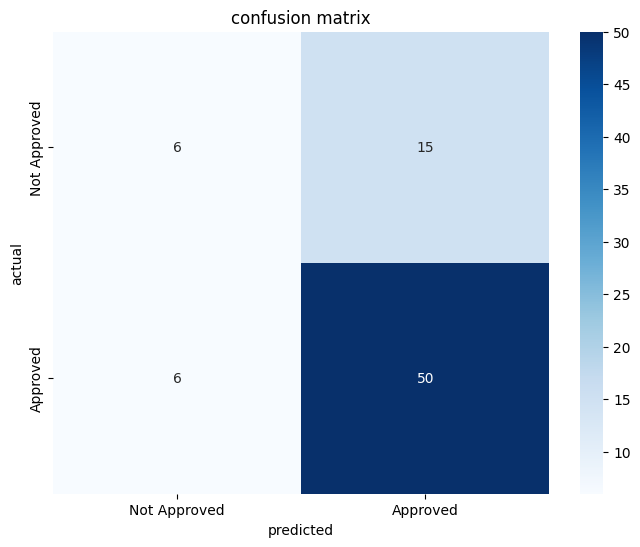

In [34]:
# ploting the confusion_matrix for testing data 
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_test_pred),annot=True, fmt='d' ,cmap='Blues', xticklabels=['Not Approved', 'Approved'], yticklabels=['Not Approved', 'Approved'])
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('confusion matrix')
plt.show()

**Decision Tree**

In [89]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=2, min_samples_split=2, min_samples_leaf=1, random_state=42)
model.fit(x_train, y_train)

y_train_pred =model.predict(x_train)
y_test_pred = model.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.7894736842105263
f1_score:-  0.8620689655172413
precision_score:-  0.8064516129032258
recall_score:-  0.9259259259259259
confusion matrix:-  [[ 40  48]
 [ 16 200]]
Test Accuracy:-  0.8181818181818182
f1_score:-  0.8870967741935484
precision_score:-  0.7971014492753623
recall_score:-  1.0
confusion matrix:-  [[ 8 14]
 [ 0 55]]


**SVC Support Vector Classifier**

In [66]:
from sklearn.svm import SVC 
svc = SVC(kernel='linear', random_state=42, C=1.0 )
svc.fit(x_train, y_train)

y_train_pred =svc.predict(x_train)
y_test_pred = svc.predict(x_test)

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.743421052631579
f1_score:-  0.8326180257510729
precision_score:-  0.776
recall_score:-  0.8981481481481481
confusion matrix:-  [[ 32  56]
 [ 22 194]]
Test Accuracy:-  0.8181818181818182
f1_score:-  0.8852459016393442
precision_score:-  0.8059701492537313
recall_score:-  0.9818181818181818
confusion matrix:-  [[ 9 13]
 [ 1 54]]


**XGBoost Classifier**

In [33]:
import joblib 
from xgboost import XGBClassifier 
xgb = XGBClassifier(n_estimators=70, learning_rate=0.1, max_depth =3,random_state=42)
xgb.fit(x_train, y_train)

y_train_pred =xgb.predict(x_train)
y_test_pred = xgb.predict(x_test)

# saving the model 
joblib.dump(xgb, 'loan_approval_model.joblib')

# training evalution 
print("Train Accuracy:- ", accuracy_score(y_train, y_train_pred))
print("f1_score:- ",f1_score(y_train, y_train_pred))
print("precision_score:- ", precision_score(y_train, y_train_pred))
print("recall_score:- ", recall_score(y_train, y_train_pred))
print("confusion matrix:- ",confusion_matrix(y_train, y_train_pred))

# testing evalution
print("Test Accuracy:- ", accuracy_score(y_test, y_test_pred))
print("f1_score:- ",f1_score(y_test, y_test_pred))
print("precision_score:- ", precision_score(y_test, y_test_pred))
print("recall_score:- ", recall_score(y_test, y_test_pred))
print("confusion matrix:- ",confusion_matrix(y_test, y_test_pred))

Train Accuracy:-  0.8782894736842105
f1_score:-  0.9186813186813186
precision_score:-  0.8744769874476988
recall_score:-  0.9675925925925926
confusion matrix:-  [[ 58  30]
 [  7 209]]
Test Accuracy:-  0.8311688311688312
f1_score:-  0.8925619834710744
precision_score:-  0.8181818181818182
recall_score:-  0.9818181818181818
confusion matrix:-  [[10 12]
 [ 1 54]]


In [88]:
# grid search for xgboost 
from sklearn.model_selection import GridSearchCV
param = {
    'n_estimators': [10,50,60,70,80,100],
    'learning_rate': [0.01, 0.1, 0.2, 0.3],
    'max_depth': [3, 4, 5, 6, 7]
}

grid = GridSearchCV(estimator=XGBClassifier(random_state=42), param_grid=param, cv=3, n_jobs=-1, verbose=2, scoring='accuracy')
grid.fit(x_train, y_train)
print('Best score', grid.best_score_)
print("Best parameter:- ",grid.best_params_)

Fitting 3 folds for each of 120 candidates, totalling 360 fits
Best score 0.7533488642981946
Best parameter:-  {'learning_rate': 0.3, 'max_depth': 7, 'n_estimators': 70}


In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    xgb,
    x,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1": make_scorer(f1_score),
        "precision": make_scorer(precision_score),
        "recall": make_scorer(recall_score),
    }
)

for metric in ["test_accuracy", "test_f1", "test_precision", "test_recall"]:
    print(metric, scores[metric].mean(), scores[metric].std())

test_accuracy 0.7532125768967874 0.026073755369213397
test_f1 0.8369638039956732 0.01954042376964727
test_precision 0.7886014032520865 0.015799285100289343
test_recall 0.8927272727272728 0.0397845892916228


In [ ]:
y_test_probability = xgb.predict_proba(x_test)[:, 1] 

threshold = 0.70
y_test_pred_custom = (y_test_probability >= threshold).astype(int)

In [22]:
y_test_pred_custom

array([1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0])

In [23]:
# confusion_matrix
confusion_matrix(y_test, y_test_pred_custom)

array([[14,  8],
       [ 7, 48]])

In [24]:
from sklearn.model_selection import cross_val_predict 
from sklearn.metrics import classification_report, balanced_accuracy_score

y_pred = cross_val_predict(
    xgb,
    x,
    y,
    cv=cv
)

print(classification_report(y, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y, y_pred))

              precision    recall  f1-score   support

           0       0.61      0.41      0.49       110
           1       0.79      0.89      0.84       271

    accuracy                           0.75       381
   macro avg       0.70      0.65      0.66       381
weighted avg       0.74      0.75      0.74       381

Balanced accuracy: 0.651039919490104


In [30]:
print(classification_report(y_test, y_test_pred_custom))

              precision    recall  f1-score   support

           0       0.67      0.64      0.65        22
           1       0.86      0.87      0.86        55

    accuracy                           0.81        77
   macro avg       0.76      0.75      0.76        77
weighted avg       0.80      0.81      0.80        77



In [27]:
y_test.value_counts()

Loan_Status_Y
1    55
0    22
Name: count, dtype: int64

In [28]:
y_train.value_counts()

Loan_Status_Y
1    216
0     88
Name: count, dtype: int64

In [31]:
accuracy_score(y_test, y_test_pred_custom)

0.8051948051948052

In [ ]:
y_test_pred_custom.value_counts()

Count 1  56
Count 0  21


In [38]:
import joblib
test = [[3510, 0, 76, 360, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]]
model = joblib.load('D:\\CODING\\ML using Python\\Venv\\Code\\projects\\loan_approval_model.joblib')
pred = model.predict(test)
print(pred[0])
print(model.predict_proba(test)[0][0]*100)
threshold = 0.7
pred_custom = model.predict_proba(test)[0][1] if model.predict_proba(test)[0][1] >= threshold else 0
print(pred_custom)  

0
56.901596
0
